In [1]:
import pandas as pd
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Adding qid

In [5]:
query_df = pd.read_csv("Data/query_formulation_df.csv")
serp_df = pd.read_csv("Data/logs_compiled.csv")
queries = pd.read_csv("Data/query_df.csv")
query_df["qid"] = [serp_df.loc[serp_df["serp_id"]==serp_id]["qid"].values[0] for serp_id in query_df["serp_id"]]
query_df["timestamp"] = [queries.loc[queries["qid"]==qid]["timestamp"].values[0] for qid in query_df["qid"]]
query_df = query_df[["uid","topic_number","qid","query", "timestamp", "serp_id", "precision@10"]]
query_df = query_df.sort_values(["uid", "timestamp"]).reset_index(drop=True)
query_df.to_csv("Data/query_formulation_df.csv", index=False, encoding="utf8")
query_df.head(10)

,uid,topic_number,qid,query,timestamp,serp_id,precision@10
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,2026-05-19 14:51:26.583,serp1,0.2
1,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,2026-05-19 15:02:41.120,serp2,0.1
2,1,g3t1,q3,Fiume sacro degli indiani,2026-05-19 15:08:39.525,serp3,0.4
3,2,g3t3,q4,Quali sono i animali dall'India,2026-05-19 14:50:22.081,serp4,0.7
4,2,g3t3,q5,Quali sono i 5 animali tipici dall'India,2026-05-19 14:51:20.189,serp5,0.2
5,2,g3t2,q6,Qual è il nome del simbolo al centro della ban...,2026-05-19 15:05:41.521,serp6,0.4
6,2,g3t2,q7,Qual è il nome del simbolo al centro della b...,2026-05-19 15:09:06.317,serp7,0.4
7,2,g3t1,q8,Come si chiama il fiume sacro agli indiani,2026-05-19 15:14:10.201,serp8,0.4
8,3,g3t1,q9,come si chiama il fiume sacro agli indiani,2026-05-19 14:50:09.786,serp9,0.4
9,3,g3t3,q10,Quali sono 5 animali tipici dell'india,2026-05-19 14:53:41.858,serp10,0.2


In [4]:
query_df.loc[query_df["qid"]=="q10"]

,uid,topic_number,qid,query,timestamp,serp_id,precision@10
11,3,g3t3,q10,Quali sono 5 animali tipici dell'india,2026-05-19 14:53:41.858,serp10,0.2


## Analysing queries

In [6]:
import pandas as pd
import numpy as np
from driver import get_text_stats
import language_tool_python
from Levenshtein import distance
from tqdm.notebook import tqdm
import spacy

nlp = spacy.load("it_core_news_lg")
tool = language_tool_python.LanguageTool('it')

query_df = pd.read_csv("Data/query_formulation_df.csv")
concreteness = pd.read_excel("Resources/IT_concreteness_database.xlsx")
text_stat_results = get_text_stats(query_df, "query")

query_df["query_len"] = text_stat_results["content_len"]
query_df["mean_aoa"] = text_stat_results["mean_aoa"]
query_df["mean_conc"] = text_stat_results["mean_conc"]
query_df["gulpease_index"] = text_stat_results["gulpease_index"]

corrected_query_list = []
num_typos = []
levenshtein_dist = []
lex_density = []
lex_diversity = []
ttr = []
stop_word_ratio = []
num_concepts = []
concepts = []
mean_concepts_conc = []
# query_len = []


for _, row in tqdm(query_df.iterrows(), total=len(query_df)):
    query = row["query"]
    corrected_query = tool.correct(query)
    if query.lower() == corrected_query.lower():
        corrected_query_list.append("")
        num_typos.append(0)
    else:
        corrected_query_list.append(corrected_query)
        matches = tool.check(query)
        num_typos.append(len(matches))
    levenshtein_dist.append(distance(query.lower(), corrected_query.lower()))
    doc = nlp(query)

    lex_words = [] # lexical words, i.e., nouns, verbs, adjectives, and adverbs

    words = []

    # Extract noun chunks
    noun_phrases = [chunk.text for chunk in doc.noun_chunks]

    # get the concreteness of each noun chunk
    noun_phrases_conc = []
    for phrase in noun_phrases:
        phrase_conc = []
        phrase_doc = nlp(phrase)
        for phrase_token in phrase_doc:
            if phrase_token.text.lower() in concreteness["Ita_Word"].tolist():
                phrase_conc.append(concreteness.loc[concreteness["Ita_Word"]==phrase_token.text.lower()]["M_Con"].values[0])
        if len(phrase_conc) == 0: # none of the words in the noun chunk have a concreteness value
            noun_phrases_conc.append(None)
        else:
            noun_phrases_conc.append(np.mean(phrase_conc))

    stop_word_count = 0
    for token in doc:
        # print(token.text, token.pos_, token.tag_)
        if token.pos_ in ["ADJ", "ADV", "NOUN", "PROPN", "VERB", "AUX"]:
            lex_words.append(token.text.strip().lower())
        if token.pos_ not in ["SYM", "X", "PUNCT"]:
            words.append(token.text.strip().lower())
        if token.is_stop:
            stop_word_count += 1

    assert len(words) == row["query_len"] # number of words should be same as query length

    # query_len.append(len(words)-stop_word_count) # query length = number of non stop words
    lex_density.append(len(lex_words)/len(words))
    ttr.append(len(set(words))/len(words)) # type token ratio: num of unique words/total num of words
    lex_diversity.append(len(set(lex_words))/len(lex_words)) # lexical diversity: num of unique lexical words/total num of lexical words
    stop_word_ratio.append(stop_word_count/len(words))
    num_concepts.append(len(noun_phrases))
    concepts.append(noun_phrases)
    mean_concepts_conc.append(pd.Series(noun_phrases_conc).dropna().mean())
    # print(query, corrected_query, len(matches), distance(query, corrected_query))

# query_df["query_len"] = query_len
query_df["lex_density"] = lex_density
query_df["lex_diversity"] = lex_diversity
query_df["ttr"] = ttr
query_df["stop_word_ratio"] = stop_word_ratio
query_df["corrected_query"] = corrected_query_list
query_df["num_typos"] = num_typos
query_df["levenshtein_dist"] = levenshtein_dist
query_df["num_concepts"] = num_concepts
query_df["concepts"] = concepts
query_df["mean_concepts_conc"] = mean_concepts_conc

query_df["effective_query"] = [int(p10 >= 0.8) for p10 in query_df["precision@10"]]

  0%|          | 0/118 [00:00<?, ?it/s]

  0%|          | 0/118 [00:00<?, ?it/s]

In [7]:
query_df.head(2)

,uid,topic_number,qid,query,timestamp,serp_id,precision@10,query_len,mean_aoa,mean_conc,...,lex_diversity,ttr,stop_word_ratio,corrected_query,num_typos,levenshtein_dist,num_concepts,concepts,mean_concepts_conc,effective_query
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,2026-05-19 14:51:26.583,serp1,0.2,8,NaN,NaN,...,1.0,1.0,0.375000,,0,0,3,"[Quali, i cinque animali tipici, india]",NaN,0
1,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,2026-05-19 15:02:41.120,serp2,0.1,11,5.12,5.3,...,1.0,1.0,0.545455,Quale è il nome del simbolo al centro della ba...,1,1,6,"[Quale, il nome, simbolo, centro, bandieradel,...",5.3,0


In [8]:
query_df.to_csv("Data/query_formulation_df.csv", index=False, encoding="utf8")
query_df.head()

,uid,topic_number,qid,query,timestamp,serp_id,precision@10,query_len,mean_aoa,mean_conc,...,lex_diversity,ttr,stop_word_ratio,corrected_query,num_typos,levenshtein_dist,num_concepts,concepts,mean_concepts_conc,effective_query
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,2026-05-19 14:51:26.583,serp1,0.2,8,NaN,NaN,...,1.0,1.0,0.375000,,0,0,3,"[Quali, i cinque animali tipici, india]",NaN,0
1,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,2026-05-19 15:02:41.120,serp2,0.1,11,5.12,5.3,...,1.0,1.0,0.545455,Quale è il nome del simbolo al centro della ba...,1,1,6,"[Quale, il nome, simbolo, centro, bandieradel,...",5.3,0
2,1,g3t1,q3,Fiume sacro degli indiani,2026-05-19 15:08:39.525,serp3,0.4,4,4.80,7.5,...,1.0,1.0,0.250000,,0,0,2,"[Fiume sacro, indiani]",7.5,0
3,2,g3t3,q4,Quali sono i animali dall'India,2026-05-19 14:50:22.081,serp4,0.7,6,NaN,NaN,...,1.0,1.0,0.500000,,0,0,3,"[Quali, i animali, India]",NaN,0
4,2,g3t3,q5,Quali sono i 5 animali tipici dall'India,2026-05-19 14:51:20.189,serp5,0.2,8,NaN,NaN,...,1.0,1.0,0.375000,,0,0,3,"[Quali, i 5 animali tipici, India]",NaN,0


In [9]:
query_df_sample = query_df.sample(5, random_state=67).sort_index()
query_df_sample

,uid,topic_number,qid,query,timestamp,serp_id,precision@10,query_len,mean_aoa,mean_conc,...,lex_diversity,ttr,stop_word_ratio,corrected_query,num_typos,levenshtein_dist,num_concepts,concepts,mean_concepts_conc,effective_query
3,2,g3t3,q4,Quali sono i animali dall'India,2026-05-19 14:50:22.081,serp4,0.7,6,NaN,NaN,...,1.0,1.000000,0.500000,,0,0,3,"[Quali, i animali, India]",NaN,0
47,8,g3t2,q48,Come si chiama il nome del disegno nel centro ...,2026-05-19 15:08:34.999,serp48,0.0,13,4.080000,6.575,...,1.0,1.000000,0.538462,,0,0,5,"[il nome, disegno, centro, bandiera, India]",6.575,0
72,12,g4t2,q73,Qual è stato il primo animale nello spazio e c...,2026-05-19 10:52:04.208,serp73,0.3,12,4.500000,4.750,...,1.0,1.000000,0.666667,,0,0,3,"[Qual, il primo animale, spazio]",4.750,0
77,12,g4t3,q78,3 galassie oltre alla nostra,2026-05-19 11:17:32.368,serp78,0.5,5,NaN,NaN,...,1.0,1.000000,0.600000,,0,0,1,[3 galassie],NaN,0
115,18,g3t2,q116,Quale il nome del simbolo al centro della band...,2026-05-19 15:09:14.538,serp116,0.4,11,5.066667,6.575,...,1.0,0.909091,0.545455,Quale il nome del simbolo al centro della band...,1,1,5,"[il nome, simbolo, centro, bandiera, lindia]",6.575,0


In [10]:
query_df.loc[query_df["effective_query"]==1]

,uid,topic_number,qid,query,timestamp,serp_id,precision@10,query_len,mean_aoa,mean_conc,...,lex_diversity,ttr,stop_word_ratio,corrected_query,num_typos,levenshtein_dist,num_concepts,concepts,mean_concepts_conc,effective_query
17,4,g3t1,q18,Fiume sacro indiano,2026-05-19 15:20:20.872,serp18,0.8,3,4.80,7.50,...,1.0,1.0,0.000000,,0,0,1,[Fiume sacro],7.50,1
37,6,g3t2,q38,Simbolo andiera India,2026-05-19 15:09:52.643,serp38,0.8,3,6.60,NaN,...,1.0,1.0,0.000000,Simbolo bandiera India,1,1,2,"[Simbolo, India]",NaN,1
38,7,g3t2,q39,il simbolo della baniera dell dell'india,2026-05-19 14:52:29.403,serp39,0.8,7,6.60,NaN,...,1.0,1.0,0.571429,Il simbolo della Baviera dell'india,3,6,3,"[il simbolo, baniera, india]",NaN,1
39,7,g3t2,q40,il simbolo della baniera dell dell'india,2026-05-19 14:53:01.273,serp40,0.8,7,6.60,NaN,...,1.0,1.0,0.571429,Il simbolo della Baviera dell'india,3,6,3,"[il simbolo, baniera, india]",NaN,1
49,8,g3t2,q50,centro bandiera india simbolo,2026-05-19 15:11:39.971,serp50,0.9,4,5.78,7.85,...,1.0,1.0,0.000000,,0,0,1,[centro bandiera india],7.85,1
50,8,g3t2,q51,Bandira india simbolo,2026-05-19 15:14:06.749,serp51,0.8,3,6.60,NaN,...,1.0,1.0,0.000000,Bandirà india simbolo,1,1,2,"[Bandira, india]",NaN,1
51,8,g3t1,q52,Fiume sacro India,2026-05-19 15:16:00.828,serp52,0.8,3,4.80,7.50,...,1.0,1.0,0.000000,,0,0,2,"[Fiume sacro, India]",7.50,1
52,8,g3t1,q53,Fiume sacro India,2026-05-19 15:16:17.475,serp53,0.8,3,4.80,7.50,...,1.0,1.0,0.000000,,0,0,2,"[Fiume sacro, India]",7.50,1
116,18,g3t2,q117,Simbolo della bandiera dell'india,2026-05-19 15:13:42.292,serp117,0.9,5,5.78,7.85,...,1.0,1.0,0.400000,,0,0,3,"[Simbolo, bandiera, india]",7.85,1


## Visualisation

In [3]:
import pandas as pd

query_df = pd.read_csv("Data/query_formulation_df.csv")
categories = [
    # language fluency
    "lex_density", "mean_aoa", "gulpease_index", 
    # "lex_diversity", "ttr", 
    "num_typos", "levenshtein_dist",

    # query intent complexity
    "num_concepts", "mean_concepts_conc", "query_len", "stop_word_ratio", 
    # "mean_conc",
    ]

In [4]:
len(query_df.loc[query_df["effective_query"]==1])

9

### RQ1

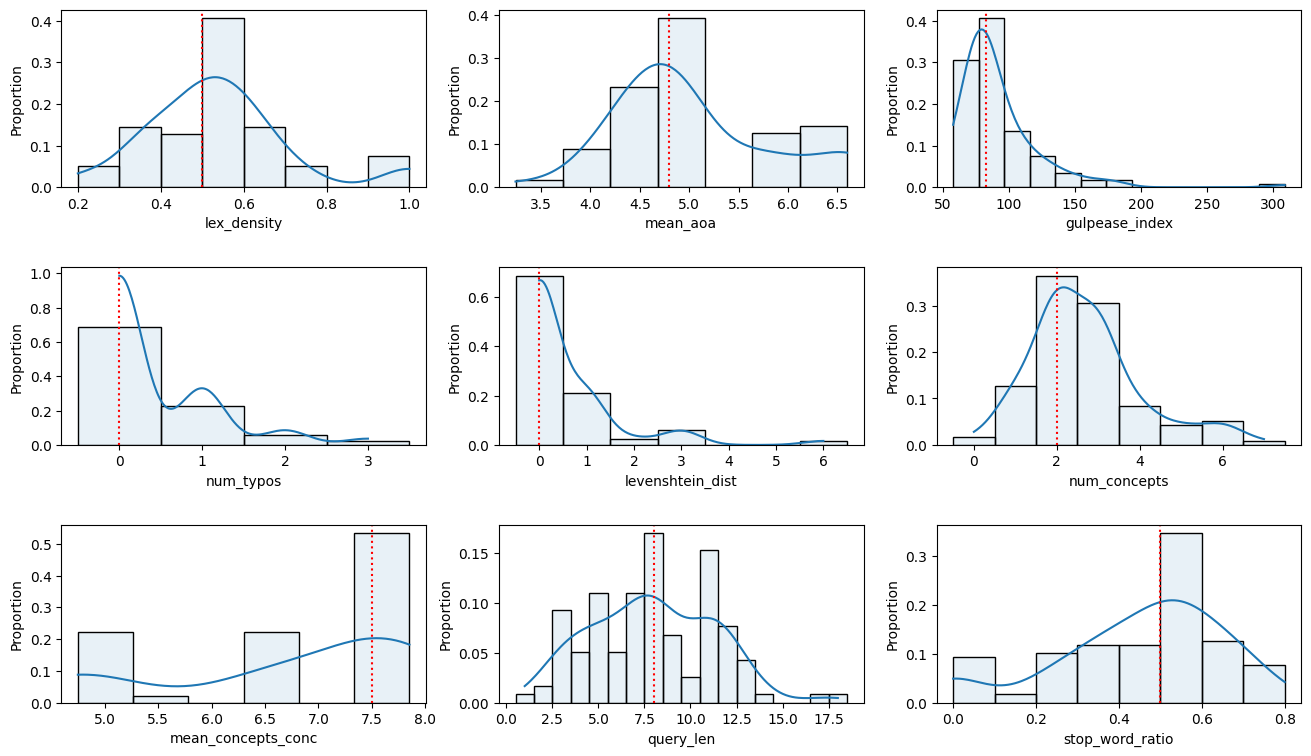

,category,mean,std_dev,max,min,median,modes
0,lex_density,0.540904,0.178568,1.00,0.20,0.50,[0.5]
1,mean_aoa,5.042619,0.813657,6.60,3.24,4.80,[4.8]
2,gulpease_index,92.104563,32.047418,309.00,57.75,82.75,[77.75]
3,num_typos,0.423729,0.720954,3.00,0.00,0.00,[0]
4,levenshtein_dist,0.542373,1.083237,6.00,0.00,0.00,[0]
5,num_concepts,2.686441,1.337808,7.00,0.00,2.00,[2]
6,mean_concepts_conc,6.708333,1.190851,7.85,4.75,7.50,[7.5]
7,query_len,7.932203,3.350542,18.00,1.00,8.00,[8]
8,stop_word_ratio,0.448541,0.201974,0.80,0.00,0.50,[0.5]


In [12]:
from driver import get_descriptive_stats

binwidth_map = {
    "lex_density": 0.1,
    # "lex_diversity": 0.01,
    # "ttr": 0.1,
    "mean_aoa": 0.5,
    "gulpease_index": 20,
    "num_typos": 1,
    "levenshtein_dist": 1,
    "query_len": 1,
    "stop_word_ratio": 0.1,
    "num_concepts": 1,
    # "mean_conc": 0.5,
    "mean_concepts_conc": 0.5
}

desc_stats = get_descriptive_stats(df=query_df, search_stage="query_formulation", categories=categories, ncols=3, nrows=3, binwidth_map=binwidth_map)
desc_stats

In [13]:
val0 = len(query_df.loc[query_df["gulpease_index"]<80]["gulpease_index"].dropna())/len(query_df["gulpease_index"].dropna())
print(f"Ratio of queries not readable for primary school students: {val0:.2f}")

val1 = len(query_df.loc[query_df["gulpease_index"]<40]["gulpease_index"].dropna())/len(query_df["gulpease_index"].dropna())
print(f"Ratio of queries not readable for even high school graduates: {val1:.2f}")

val2 = len(query_df.loc[(query_df["gulpease_index"]<60)&(query_df["gulpease_index"]>=40)]["gulpease_index"].dropna())/len(query_df["gulpease_index"].dropna())
print(f"Ratio of queries not readable for middle school graduates but readable for high school students: {val2:.2f}")

val3 = len(query_df.loc[(query_df["gulpease_index"]<80)&(query_df["gulpease_index"]>=60)]["gulpease_index"].dropna())/len(query_df["gulpease_index"].dropna())
print(f"Ratio of queries readable for middle school students but not primary school students: {val3:.2f}")

val4 = len(query_df.loc[(query_df["gulpease_index"]>=80)]["gulpease_index"].dropna())/len(query_df["gulpease_index"].dropna())
print(f"Ratio of queries readable for primary school students: {val4:.2f}")

Ratio of queries not readable for primary school students: 0.44
Ratio of queries not readable for even high school graduates: 0.00
Ratio of queries not readable for middle school graduates but readable for high school students: 0.05
Ratio of queries readable for middle school students but not primary school students: 0.39
Ratio of queries readable for primary school students: 0.56


In [14]:
query_df["mean_concepts_conc"].value_counts()/len(query_df["mean_concepts_conc"].dropna())

mean_concepts_conc
7.500    0.311111
7.850    0.222222
4.750    0.222222
6.575    0.200000
5.300    0.022222
6.400    0.022222
Name: count, dtype: float64

In [15]:
query_df["query_len"].value_counts()/len(query_df["query_len"].dropna())

query_len
8     0.169492
11    0.152542
7     0.110169
5     0.110169
3     0.093220
12    0.076271
9     0.067797
6     0.050847
4     0.050847
13    0.042373
10    0.025424
2     0.016949
14    0.008475
18    0.008475
1     0.008475
17    0.008475
Name: count, dtype: float64

In [16]:
query_df.loc[query_df["num_typos"]>0]["num_typos"].value_counts()

num_typos
1    27
2     7
3     3
Name: count, dtype: int64

In [17]:
mistakes = len(query_df.loc[query_df["num_typos"]>0]["num_typos"].dropna())/len(query_df["num_typos"].dropna())

print(f"Ratio of queries with spelling errors: {mistakes:.2f}")

Ratio of queries with spelling errors: 0.31


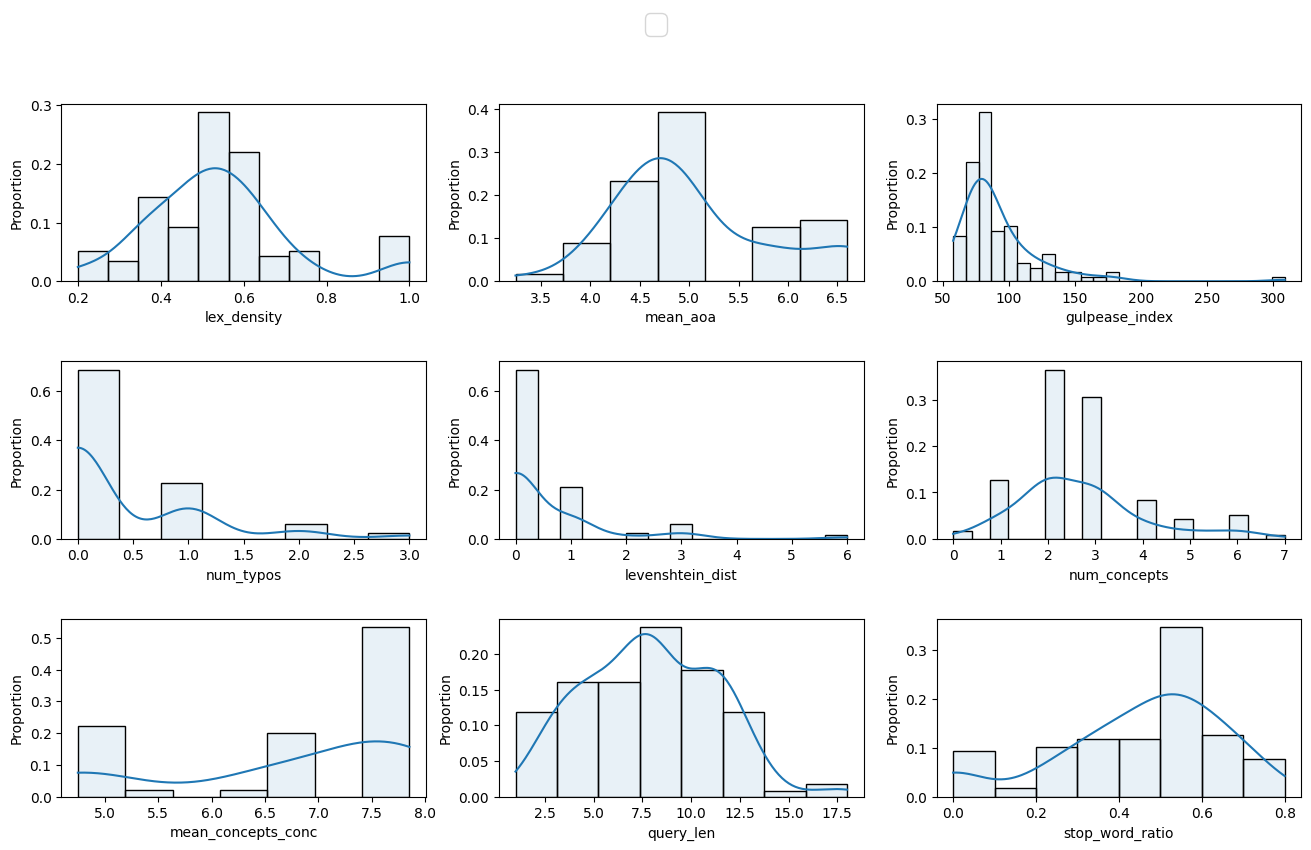

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(16,9))
plt.subplots_adjust(hspace=0.45)
for ax, category in zip(axes.flatten(), categories):
    # sns.kdeplot(data=query_df, x=category, ax=ax, cut=0, fill=True, alpha=0.25)
    sns.histplot(data=query_df, x=category, ax=ax, kde=True, alpha=0.1, stat="proportion", kde_kws={"cut":0})
    # mean = query_df[category].dropna().mean()
    # std_dev = query_df[category].dropna().std()
    # ax.axvline(mean, color="red", linestyle=":", label="mean")
    # ax.axvspan(max(mean-std_dev, query_df[category].min()), min(mean+std_dev, query_df[category].max()), color="red", alpha=0.25, label="mean ± std")

    # median = query_df[category].dropna().median()
    # mad = (query_df[category].dropna() - median).abs().median()
    # ax.axvline(median, color="green", linestyle="--", label="median")
    # ax.axvspan(max(median-mad, query_df[category].min()), min(median+mad, query_df[category].max()), color="green", alpha=0.25, label="median ± MAD")
    
    ax.set_xlabel(category)
handles, labels = ax.get_legend_handles_labels()
plt.figlegend(handles, labels, loc="upper center", ncol=4, fontsize=20)
plt.show()

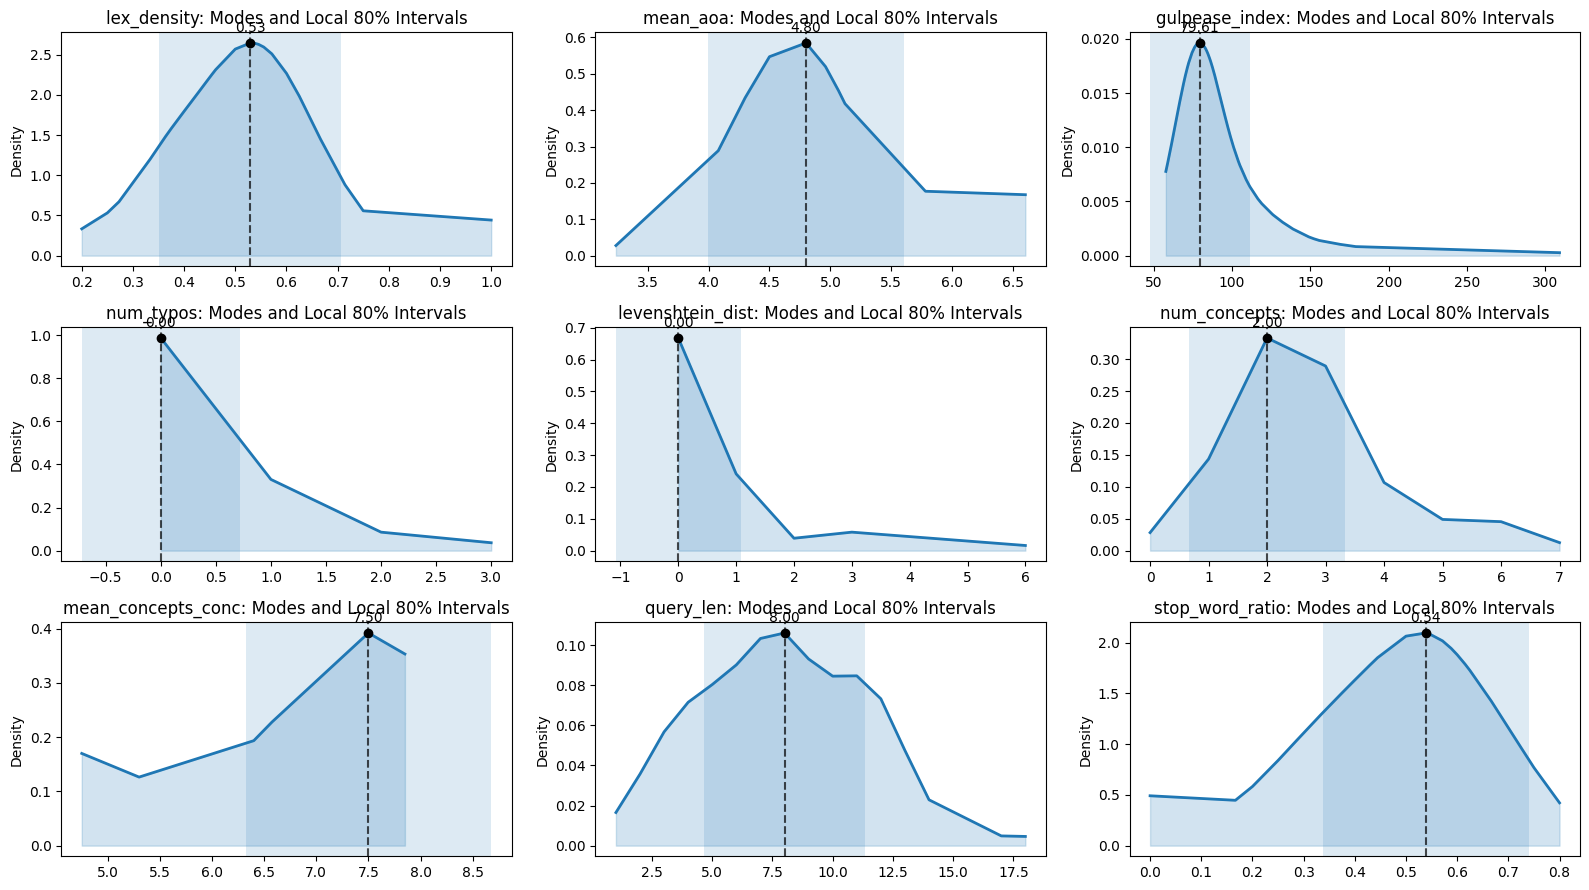

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import gaussian_kde
from scipy.signal import find_peaks


fig, axes = plt.subplots(ncols=3, nrows=3, figsize=(16,9))

for ax, col in zip(axes.flatten(), categories):

    x = query_df[col].dropna().values

    # KDE
    kde = gaussian_kde(x)
    # xs = np.linspace(x.min(), x.max(), 1000)
    xs = np.sort(x)
    ys = kde(xs)

    # Find local maxima
    peak_idx, props = find_peaks(
        ys,
        prominence=0.05 * ys.max(), # adjust as needed
        # distance=int(0.1*len(xs))
    )

    peaks = xs[peak_idx]

    if len(peaks) == 0:
        peaks = np.array([xs[np.argmax(ys)]])

    # Assign each observation to nearest peak
    peak_assignments = peaks[np.argmin(np.abs(x[:, None] - peaks), axis=1)]

    # Plot KDE
    # fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(xs, ys, color="tab:blue", lw=2)
    ax.fill_between(xs, ys, alpha=0.2, color="tab:blue")

    for peak in peaks:

        cluster = x[peak_assignments == peak]

        # # Skip tiny clusters
        # if len(cluster) < 10:
        #     continue

        cluster_std = np.std(cluster)

        # p10 = np.percentile(cluster, 10)
        # p90 = np.percentile(cluster, 90)

        # Shade local 80% interval
        ax.axvspan(
            peak-cluster_std,
            peak+cluster_std,
            alpha=0.15
        )

        # Mark mode
        peak_height = kde(peak)[0]

        ax.plot(
            peak,
            peak_height,
            "ko",
            markersize=6
        )

        ax.axvline(
            peak,
            color="black",
            linestyle="--",
            alpha=0.7
        )

        ax.text(
            peak,
            peak_height * 1.05,
            f"{peak:.2f}",
            ha="center"
        )

    ax.set_title(f"{col}: Modes and Local 80% Intervals")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

### RQ2

In [5]:
from driver import get_significance

desc_stats_df, sig_test_results = get_significance(df=query_df, effective_label="effective_query", search_stage="query_formulation", categories=categories)
sig_test_results

c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,search_stage,characteristic,test_statistic,pval,significant
0,query_formulation,lex_density,-0.500000,0.0004,True
1,query_formulation,mean_aoa,-0.980000,0.2046,False
2,query_formulation,gulpease_index,-44.166667,0.0024,True
3,query_formulation,num_typos,0.000000,1.0000,False
4,query_formulation,levenshtein_dist,0.000000,1.0000,False
5,query_formulation,num_concepts,1.000000,0.5330,False
6,query_formulation,mean_concepts_conc,-0.925000,0.0626,False
7,query_formulation,query_len,5.000000,0.0018,True
8,query_formulation,stop_word_ratio,0.500000,0.0004,True


In [6]:
desc_stats_df

,search_stage,characteristic,ineffective_median,ineffective_MAD,effective_median,effective_MAD
0,query_formulation,lex_density,0.500,0.100,1.000000,0.000000
1,query_formulation,mean_aoa,4.800,0.300,5.780000,0.820000
2,query_formulation,gulpease_index,81.500,7.500,125.666667,13.333333
3,query_formulation,num_typos,0.000,0.000,0.000000,0.000000
4,query_formulation,levenshtein_dist,0.000,0.000,0.000000,0.000000
5,query_formulation,num_concepts,3.000,1.000,2.000000,1.000000
6,query_formulation,mean_concepts_conc,6.575,0.925,7.500000,0.000000
7,query_formulation,query_len,8.000,3.000,3.000000,0.000000
8,query_formulation,stop_word_ratio,0.500,0.125,0.000000,0.000000


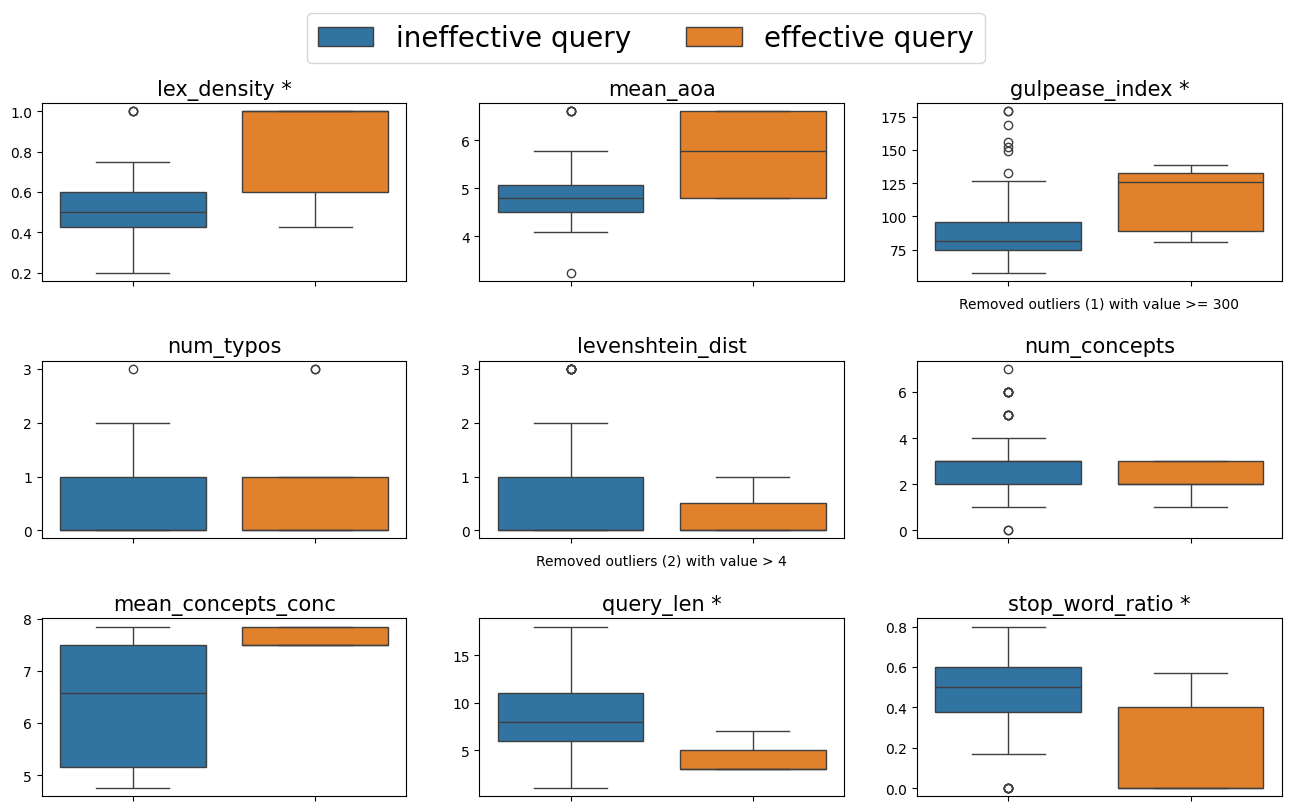

In [7]:
from driver import get_boxplots

get_boxplots(query_df, "query_formulation", categories, "effective_query", artefact="query", n_cols=3, n_rows=3, stats_df=sig_test_results)

In [ ]:
# from scipy.stats import spearmanr

# for category in categories:
#     res = spearmanr(query_df["precision@10"], query_df[category], nan_policy="omit")
#     print(f"Category: {category}; \tcoefficient: {res.statistic}; \tpval: {res.pvalue}")